<a href="https://colab.research.google.com/github/AristidesNieto/AI_Foundation_Project/blob/caspar/01_eda_inspected_district_caspar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
#C1
import pandas as pd
from google.colab import files
df = pd.read_csv('inspected_trees.csv')

labels = df["infested"].astype("string").str.strip().str.lower()
yes_count = (labels == "yes").sum()
no_count = (labels == "no").sum()
missing_count = labels.isna().sum()
print("Amount of rows: ", len(df))
print("Amount of infested trees: ", yes_count)
print("Amount of healthy trees: ", no_count)
print("Amount of missing rows: ", missing_count)
print("Ratio between healthy and infested trees: ", yes_count / no_count)


Amount of rows:  600
Amount of infested trees:  255
Amount of healthy trees:  345
Amount of missing rows:  0
Ratio between healthy and infested trees:  0.7391304347826086


In [18]:
#C2
df_bore_dust = pd.read_csv('district_trees.csv')

#Statistiken für bore_dust
labels_bore_dust = df_bore_dust["bore_dust"].astype("string").str.strip().str.lower()
found_count_bore_dust = (labels_bore_dust == "found").sum()
not_found_count_bore_dust = (labels_bore_dust == "not found").sum()
missing_count_bore_dust = labels_bore_dust.isna().sum()
print("Amount of trees with bore dust: ", found_count_bore_dust)
print("Amount of trees without bore dust: ", not_found_count_bore_dust)
print("Amount of missing rows: ", missing_count_bore_dust)
print("Ratio between trees with bore dust and without: ", found_count_bore_dust / not_found_count_bore_dust)

#Statistiken für übrige Spalten
print("\nStatistics in file inspected_trees.csv: ")
display(df.describe())
print("\nMissing values in inspected_trees.csv: ")
display(df.isna().sum())
print("\nStatistics in file district_trees.csv: ")
display(df_bore_dust.describe())
print("\nMissing values in file district_trees.csv: ")
display(df_bore_dust.isna().sum())




Amount of trees with bore dust:  58
Amount of trees without bore dust:  271
Amount of missing rows:  3338
Ratio between trees with bore dust and without:  0.2140221402214022

Statistics in file inspected_trees.csv: 


,survey_batch,east,north,altitude_m,spruce_share,water_deficit_mm,diameter_cm,height_m
count,600.000000,6.000000e+02,6.000000e+02,600.000000,600.000000,600.000000,600.000000,529.000000
mean,2.610000,2.645345e+06,1.195525e+06,1210.925000,72.683333,117.233333,110.750500,26.164839
std,1.110535,6.419299e+02,6.242514e+02,156.943157,18.239724,20.170779,154.647389,13.470493
min,1.000000,2.644104e+06,1.194110e+06,907.000000,35.000000,67.000000,2.800000,0.000000
25%,2.000000,2.644870e+06,1.195112e+06,1086.000000,60.000000,103.000000,26.600000,21.400000
50%,3.000000,2.645321e+06,1.195537e+06,1222.000000,75.000000,118.000000,38.350000,26.400000
75%,4.000000,2.645888e+06,1.196067e+06,1343.500000,90.000000,132.000000,69.850000,30.900000
max,4.000000,2.646598e+06,1.196593e+06,1451.000000,100.000000,156.000000,784.000000,273.000000



Missing values in inspected_trees.csv: 


,0
tree_id,0
crew,0
survey_batch,0
east,0
north,0
altitude_m,0
aspect,0
spruce_share,0
water_deficit_mm,0
diameter_cm,0



Statistics in file district_trees.csv: 


,survey_batch,east,north,altitude_m,spruce_share,water_deficit_mm,diameter_cm,height_m
count,3667.000000,3.667000e+03,3.667000e+03,3667.000000,3667.000000,3667.000000,3667.000000,3292.000000
mean,2.509681,2.645399e+06,1.195549e+06,1206.251977,73.029725,115.085083,107.853613,25.996203
std,1.116802,6.864700e+02,6.272114e+02,148.285916,18.266304,21.352250,145.234689,16.505861
min,1.000000,2.644100e+06,1.194101e+06,905.000000,35.000000,67.000000,3.000000,0.000000
25%,2.000000,2.644840e+06,1.195105e+06,1087.000000,60.000000,101.000000,25.300000,21.200000
50%,3.000000,2.645450e+06,1.195595e+06,1218.000000,75.000000,116.000000,36.100000,25.800000
75%,4.000000,2.645965e+06,1.196085e+06,1321.500000,90.000000,131.000000,145.000000,30.400000
max,4.000000,2.646598e+06,1.196599e+06,1451.000000,100.000000,156.000000,775.000000,373.000000



Missing values in file district_trees.csv: 


,0
tree_id,0
crew,0
survey_batch,0
east,0
north,0
altitude_m,0
aspect,0
spruce_share,0
water_deficit_mm,0
diameter_cm,0


In [19]:
#C3
print(df["aspect"].value_counts(dropna=False))
print(df["crew"].value_counts(dropna=False))
print(df["survey_batch"].value_counts(dropna=False))

aspect
E        198
W        146
S        105
South     45
N         39
SÜD       34
s         33
Name: count, dtype: int64
crew
A    166
C    152
D    141
B    141
Name: count, dtype: int64
survey_batch
4    168
3    160
2    142
1    130
Name: count, dtype: int64


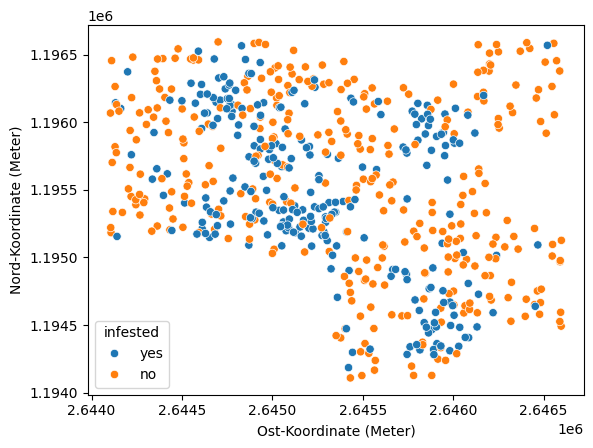

In [21]:
#C4
import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(data=df, x='east', y='north', hue='infested')
plt.xlabel("Ost-Koordinate (Meter)")
plt.ylabel("Nord-Koordinate (Meter)")
plt.show()

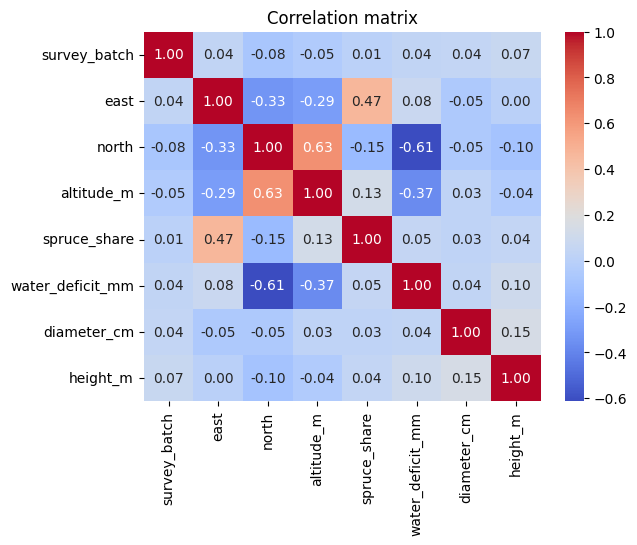

In [47]:
#C5
corr_matrix = df.select_dtypes(include=['number']).corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation matrix")
plt.show()

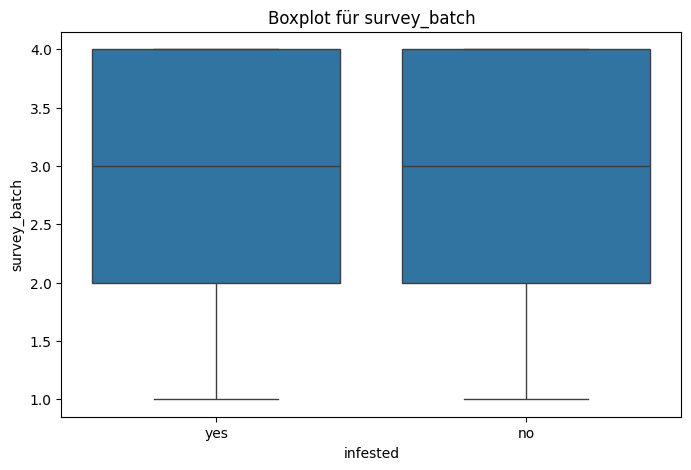

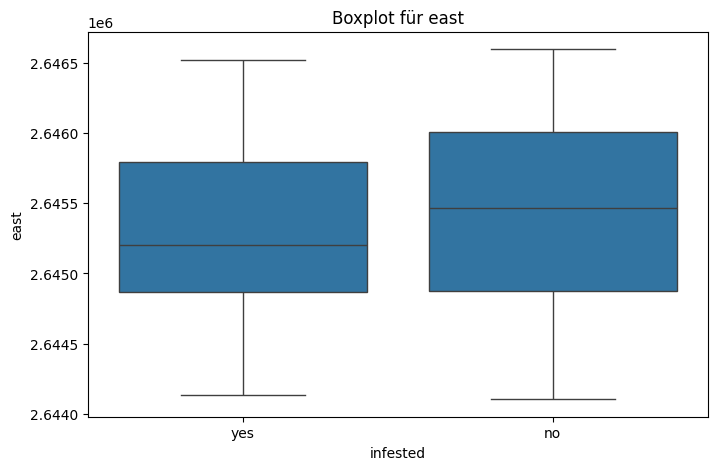

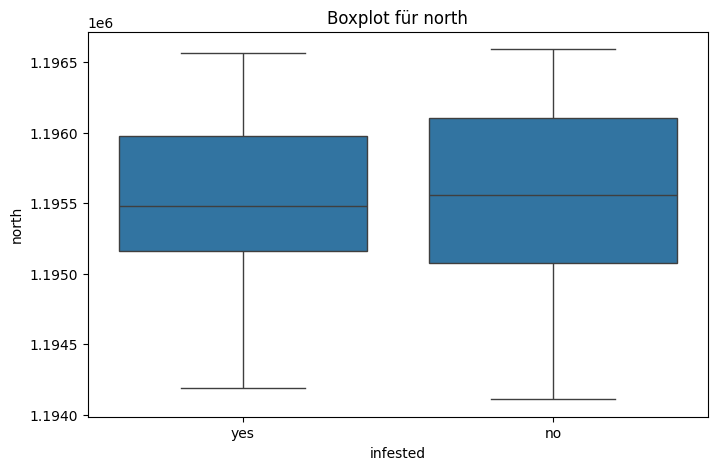

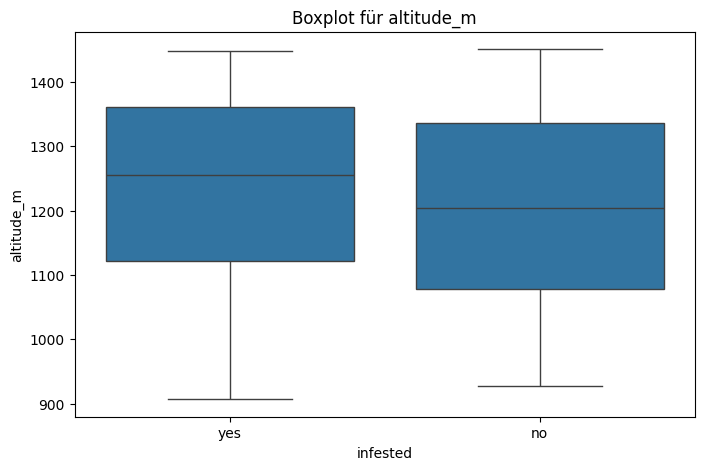

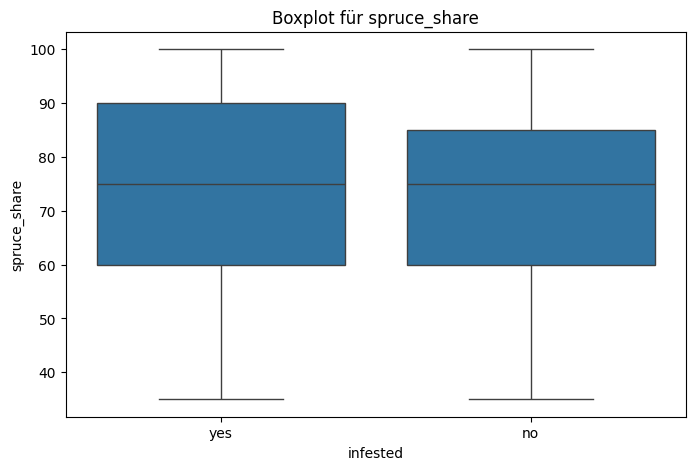

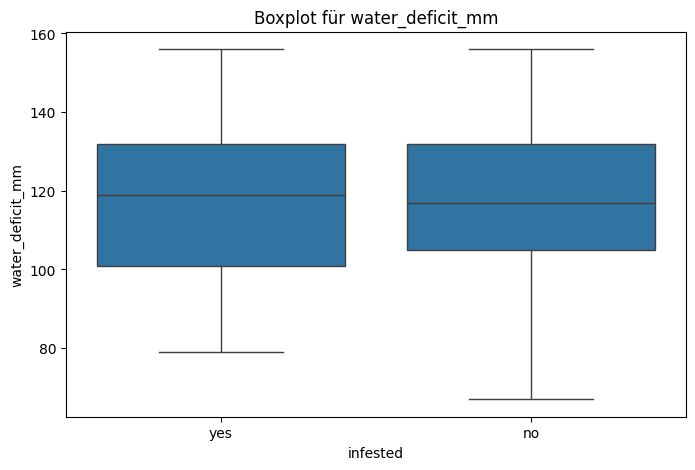

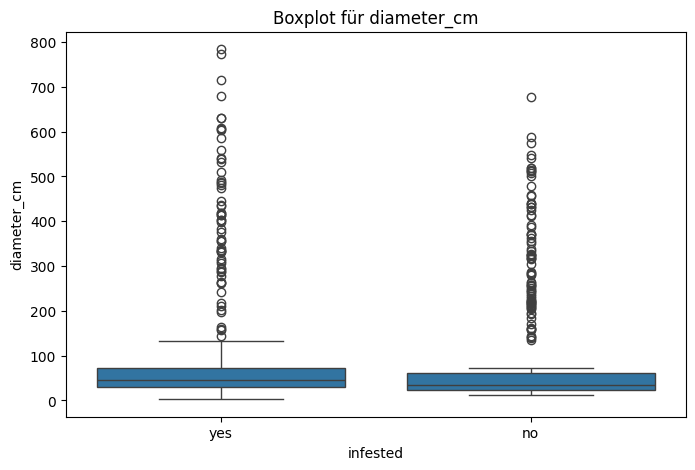

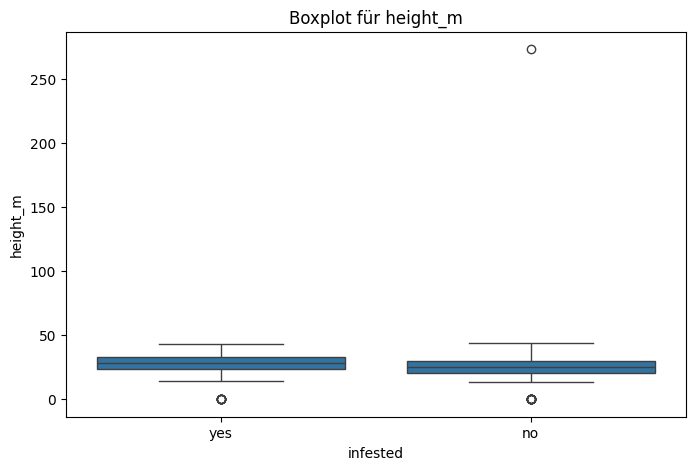

In [24]:
#C6
numeric_cols = df.select_dtypes(include=['number']).columns

for col in numeric_cols:
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=df, x='infested', y=col)
    plt.title(f"Boxplot für {col}")
    plt.show()


In [44]:
#C7
display(df.describe())
display(df_bore_dust.describe())

all_cols1 = df.select_dtypes(exclude=['number']).columns
all_cols2 = df_bore_dust.select_dtypes(exclude=['number']).columns

for col in all_cols1:
  if col == "tree_id":
    continue
  print(f"\nFor {col} column, the unique values are: \n")
  display(df[col].value_counts(dropna=False))

for col in all_cols2:
  if col == "tree_id":
    continue
  print(f"\nFor {col} column, the unique values are: \n")
  display(df_bore_dust[col].value_counts(dropna=False))



,survey_batch,east,north,altitude_m,spruce_share,water_deficit_mm,diameter_cm,height_m
count,600.000000,6.000000e+02,6.000000e+02,600.000000,600.000000,600.000000,600.000000,529.000000
mean,2.610000,2.645345e+06,1.195525e+06,1210.925000,72.683333,117.233333,110.750500,26.164839
std,1.110535,6.419299e+02,6.242514e+02,156.943157,18.239724,20.170779,154.647389,13.470493
min,1.000000,2.644104e+06,1.194110e+06,907.000000,35.000000,67.000000,2.800000,0.000000
25%,2.000000,2.644870e+06,1.195112e+06,1086.000000,60.000000,103.000000,26.600000,21.400000
50%,3.000000,2.645321e+06,1.195537e+06,1222.000000,75.000000,118.000000,38.350000,26.400000
75%,4.000000,2.645888e+06,1.196067e+06,1343.500000,90.000000,132.000000,69.850000,30.900000
max,4.000000,2.646598e+06,1.196593e+06,1451.000000,100.000000,156.000000,784.000000,273.000000


,survey_batch,east,north,altitude_m,spruce_share,water_deficit_mm,diameter_cm,height_m
count,3667.000000,3.667000e+03,3.667000e+03,3667.000000,3667.000000,3667.000000,3667.000000,3292.000000
mean,2.509681,2.645399e+06,1.195549e+06,1206.251977,73.029725,115.085083,107.853613,25.996203
std,1.116802,6.864700e+02,6.272114e+02,148.285916,18.266304,21.352250,145.234689,16.505861
min,1.000000,2.644100e+06,1.194101e+06,905.000000,35.000000,67.000000,3.000000,0.000000
25%,2.000000,2.644840e+06,1.195105e+06,1087.000000,60.000000,101.000000,25.300000,21.200000
50%,3.000000,2.645450e+06,1.195595e+06,1218.000000,75.000000,116.000000,36.100000,25.800000
75%,4.000000,2.645965e+06,1.196085e+06,1321.500000,90.000000,131.000000,145.000000,30.400000
max,4.000000,2.646598e+06,1.196599e+06,1451.000000,100.000000,156.000000,775.000000,373.000000



For crew column, the unique values are: 



,count
crew,
A,166
C,152
D,141
B,141



For aspect column, the unique values are: 



,count
aspect,
E,198
W,146
S,105
South,45
N,39
SÜD,34
s,33


... (4 outputs left out)


For aspect column, the unique values are: 



,count
aspect,
E,1316
W,700
S,645
N,356
s,224
SÜD,213
South,213



For bore_dust column, the unique values are: 



,count
bore_dust,
NaN,3338
not found,271
found,58


**Noticable things**

For inspected_trees:
*   In the 'height_m' column, values are missing
*   In the height_m column, there is a big spread in values and there are zero-values as well
*   For the 'aspect'-column, there are for different names for 'South'


For district_trees:
*   The same problems as with inspected_trees
*   'diameter_cm' does also have a big variation in data, but that can be normal for trees
*   In 'bore_dust', there are a lot missing values
*   For the 'aspect'-column, there are for different names for 'South'







In [46]:
#C8
import numpy as np

def clean_district(df_bore_dust):
  df_bore_dust['aspect'] = df_bore_dust['aspect'].replace(["s", "SÜD", "South", "s"], "S")
  df_bore_dust['height_m'] = df_bore_dust['height_m'].replace(0, np.nan).interpolate(method='linear')
  df_bore_dust['bore_dust'] = df_bore_dust['bore_dust'].fillna("missing")
  return df_bore_dust

def clean_inspected(df):
  df['aspect'] = df['aspect'].replace(["s", "SÜD", "South", "s"], "S")
  df['height_m'] = df['height_m'].replace(0, np.nan).interpolate(method='linear')
  return df


train_df_inspected_clean = clean_inspected(df)
train_df_district_clean = clean_district(df_bore_dust)


#C9
**Section 2**

Boxplots and a scatterplot have been made for the data exploration of inspected_trees.csv and district_trees.csv.

Boxplots have been made to see whether there is a relation of one of the tree properties and its infested-status. This showed that:

*   Trees in the east are - in general - less likely to be infested
*   Trees with a high altitude are - in general - a little more likely to be infested
*   Trees with a higher spruce share are - in general - more likely to be infested

A scatterplot has been made to analyse the relation between the coordinates of the trees and there infested-status. A correlation-matrix shows the most important correlations between variables, for example: there is a high correlation between 'north' and 'altitude_m', suggesting that the trees in the north are standing higher in general.

**Section 3**

An extended analysis of the data has been done and cleaning functions have been written to clean the data in inspected_trees.csv and district_trees.csv.

Firstly, an extensive statistical analysis of the data is done to analyse the data-quality and specifically the data for bore_dust, because a lot of data is missing in this column (and this data could not be analysed by numeric methods). This gives a lot of information about missing and false data.

Functions have been written to clean up the data files. For example, if in one column, multiple strings have been used for the same category, these are brought back to only one string. Furthermore, null-values are replaced by NaN-values and interpolation has been used to fill up these empty spaces.
